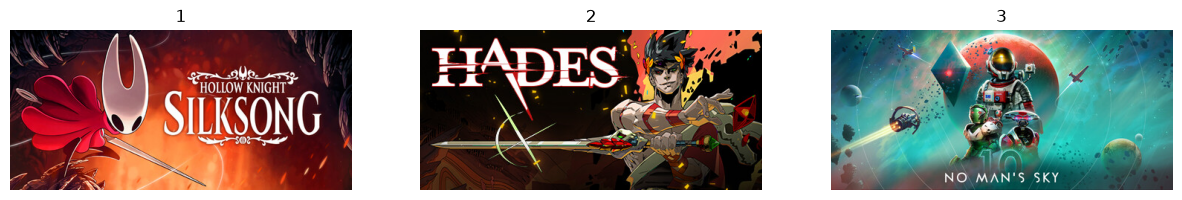

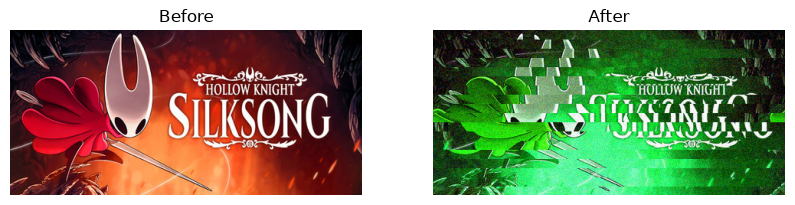

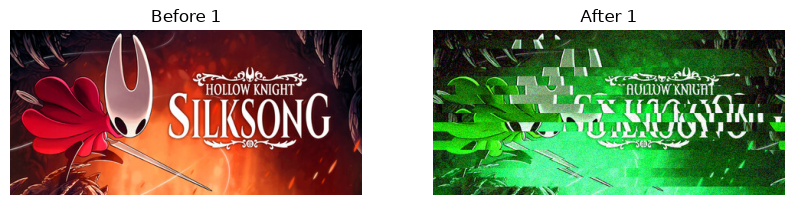

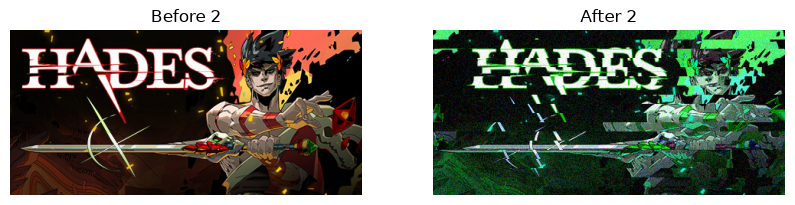

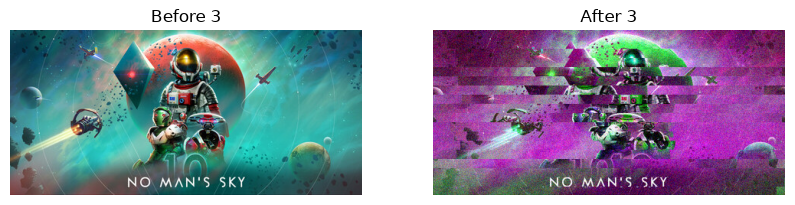

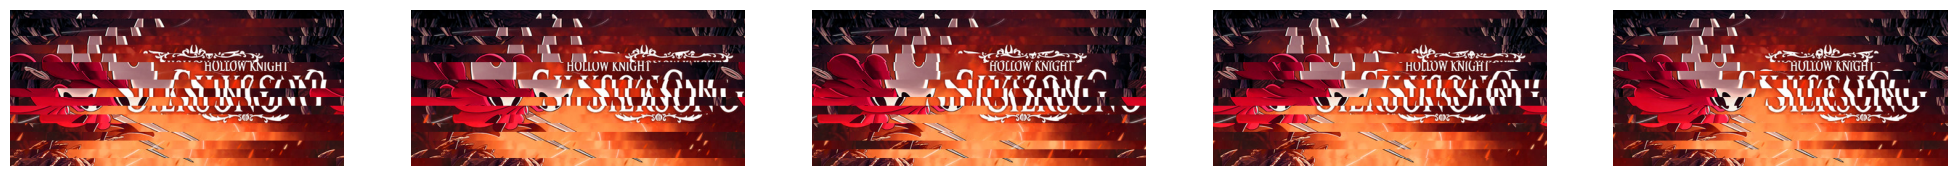

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

def load_image(path=None, max_side=600):
    """Load an image as a NumPy array (height x width x 3).
    No path? We use a sample photo of a cat from scikit-image."""
    if path:
        img = Image.open(path).convert("RGB")
    else:
        from skimage import data
        img = Image.fromarray(data.chelsea())
    img.thumbnail((max_side, max_side))          # shrink big photos so effects run fast
    return np.array(img)

def show(*images, titles=None):
    """Show one or more images side by side."""
    fig, axes = plt.subplots(1, len(images), figsize=(5 * len(images), 5))
    axes = np.atleast_1d(axes)
    for i, (ax, im) in enumerate(zip(axes, images)):
        ax.imshow(im, cmap="gray" if im.ndim == 2 else None)
        ax.set_title(titles[i] if titles else "")
        ax.axis("off")
    plt.show()

def invert(img):
    return 255 - img

def swap_channels(img, order=(2, 0, 1)):
    return img[:, :, list(order)]

def greyscale(img):
    grey = 0.299 * img[:, :, 0] + 0.587 * img[:, :, 1] + 0.114 * img[:, :, 2]
    return grey.astype(np.uint8)

def add_noise(img, amount=40):
    noise = np.random.randint(-amount, amount + 1, img.shape)
    return np.clip(img.astype(int) + noise, 0, 255).astype(np.uint8)

def row_shift_glitch(img, strength=40, band_height=12):
    out = img.copy()
    for top in range(0, img.shape[0], band_height):
        shift = np.random.randint(-strength, strength + 1)
        out[top:top + band_height] = np.roll(out[top:top + band_height], shift, axis=1)
    return out

img1 = load_image("silksong.jpg")          # replace with load_image("photo1.jpg")
img2 = load_image("hades.jpg")          # replace with load_image("photo2.jpg")
img3 = load_image("nms.jpg")          # replace with load_image("photo3.jpg")
show(img1, img2, img3, titles=["1", "2", "3"])

def my_filter(img):
    step1 = add_noise(img, 30)                   # e.g. add_noise(img, 30)
    step2 = swap_channels(step1)                 # e.g. swap_channels(step1)
    step3 = row_shift_glitch(step2, strength=40) # e.g. row_shift_glitch(step2, strength=40)
    return step3

show(img1, my_filter(img1), titles=["Before", "After"])

for i, im in enumerate([img1, img2, img3], start=1):
    out = my_filter(im)
    Image.fromarray(out).save(f"my_filter_{i}.png")
    show(im, out, titles=[f"Before {i}", f"After {i}"])

series = [row_shift_glitch(img1, strength=64) for _ in range(5)]   # choose a strength

show(*series)

for i, im in enumerate(series, start=1):
    Image.fromarray(im).save(f"glitch_series_{i}.png")